In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/CIS2334CSVdata.csv")

print(df.head())
print(df.columns)
print(df.shape)

   Abalone_id Gender  Length  Diameter  Height  Whole_weight  Shucked_weight  \
0           1      M   0.455     0.365   0.095        0.5140          0.2245   
1           2      M   0.350     0.265   0.090        0.2255          0.0995   
2           3      F   0.530     0.420   0.135        0.6770          0.2565   
3           4      M   0.440     0.365   0.125        0.5160          0.2155   
4           5      I   0.330     0.255   0.080        0.2050          0.0895   

   Viscera_weight  Shell_weight  Rings  Collector Collector_First  \
0          0.1010         0.150     15          5          Haniya   
1          0.0485         0.070      7         15           Conan   
2          0.1415         0.210      9          9          Danica   
3          0.1140         0.155     10          8            Kali   
4          0.0395         0.055      7          8            Kali   

  Collector_last               Collector_organization  Water  \
0         Talley  Prince William Sound S

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4176 entries, 0 to 4175
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Abalone_id              4176 non-null   int64  
 1   Gender                  4176 non-null   str    
 2   Length                  4176 non-null   float64
 3   Diameter                4176 non-null   float64
 4   Height                  4176 non-null   float64
 5   Whole_weight            4176 non-null   float64
 6   Shucked_weight          4176 non-null   float64
 7   Viscera_weight          4176 non-null   float64
 8   Shell_weight            4176 non-null   float64
 9   Rings                   4176 non-null   int64  
 10  Collector               4176 non-null   int64  
 11  Collector_First         4176 non-null   str    
 12  Collector_last          4176 non-null   str    
 13  Collector_organization  4176 non-null   str    
 14  Water                   4176 non-null   int64  
 15

In [3]:
df.describe()

,Abalone_id,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Collector,Water,Feb_temp
count,4176.000000,4176.000000,4176.000000,4176.000000,4176.000000,4176.000000,4176.000000,4176.000000,4176.000000,4176.000000,4176.000000,4176.000000
mean,2088.500000,0.523948,0.407846,0.139503,0.828474,0.359227,0.180547,0.238770,9.933190,8.006466,5.512213,11.873060
std,1205.651691,0.120073,0.099226,0.041823,0.490141,0.221804,0.109585,0.139163,3.224397,4.284293,2.870848,7.620718
min,1.000000,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000,1.000000,1.000000,1.900000
25%,1044.750000,0.450000,0.350000,0.115000,0.441500,0.186000,0.093375,0.130000,8.000000,4.000000,3.000000,3.600000
50%,2088.500000,0.545000,0.425000,0.140000,0.799500,0.336000,0.170750,0.233750,9.000000,8.000000,6.000000,12.800000
75%,3132.250000,0.615000,0.480000,0.165000,1.153000,0.501625,0.252625,0.328625,11.000000,12.000000,8.000000,18.000000
max,4176.000000,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000,15.000000,10.000000,24.100000


In [4]:
print(df["Gender"].value_counts())
print()
print(df["Water_region"].value_counts())

Gender
M    1527
I    1342
F    1307
Name: count, dtype: int64

Water_region
Gulf of Mexico\t          440
Southeast                 436
Pacific                   427
West Coast                419
Florida Gulf Coast        417
North Pacific             417
Florida Atlantic Coast    412
Northeast                 412
Mid-Atlantic              410
Great Lakes               386
Name: count, dtype: int64


In [5]:
correlation_columns = [
    "Length",
    "Diameter",
    "Height",
    "Whole_weight",
    "Shucked_weight",
    "Viscera_weight",
    "Shell_weight",
    "Rings",
    "Feb_temp"
]

print(
    df[correlation_columns]
    .corr()["Rings"]
    .sort_values(ascending=False)
)

Rings             1.000000
Shell_weight      0.627577
Diameter          0.574612
Height            0.557409
Length            0.556669
Whole_weight      0.540403
Viscera_weight    0.503762
Shucked_weight    0.420851
Feb_temp         -0.022387
Name: Rings, dtype: float64


In [6]:

region_age = (
    df.groupby("Water_region")["Rings"]
    .mean()
    .sort_values(ascending=False)
)

print(region_age)

Water_region
Mid-Atlantic              10.246341
Northeast                 10.053398
Florida Atlantic Coast    10.009709
Southeast                  9.990826
West Coast                 9.983294
Great Lakes                9.948187
North Pacific              9.923261
Pacific                    9.798595
Florida Gulf Coast         9.724221
Gulf of Mexico\t           9.677273
Name: Rings, dtype: float64


In [7]:
temp_age = (
    df.groupby("Water_region")[["Rings", "Feb_temp"]]
    .mean()
)

print(temp_age.sort_values("Rings", ascending=False))

                            Rings  Feb_temp
Water_region                               
Mid-Atlantic            10.246341       6.1
Northeast               10.053398       3.6
Florida Atlantic Coast  10.009709      22.1
Southeast                9.990826      12.8
West Coast               9.983294      12.3
Great Lakes              9.948187       2.5
North Pacific            9.923261       1.9
Pacific                  9.798595      24.1
Florida Gulf Coast       9.724221      18.0
Gulf of Mexico\t         9.677273      14.1


In [8]:
largest_regions = (
    df.groupby("Water_region")["Shell_weight"]
    .mean()
    .sort_values(ascending=False)
)

print(largest_regions)

Water_region
Mid-Atlantic              0.249840
Florida Atlantic Coast    0.245405
Pacific                   0.240858
Northeast                 0.239887
North Pacific             0.237332
Gulf of Mexico\t          0.236822
West Coast                0.235103
Great Lakes               0.234828
Florida Gulf Coast        0.234420
Southeast                 0.233501
Name: Shell_weight, dtype: float64


In [9]:
gender_summary = (
    df.groupby("Gender")["Rings"]
    .mean()
)

print(gender_summary)

Gender
F    11.129304
I     7.890462
M    10.704650
Name: Rings, dtype: float64


C:\Users\User\AppData\Local\Temp\ipykernel_18792\1972112411.py:10: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


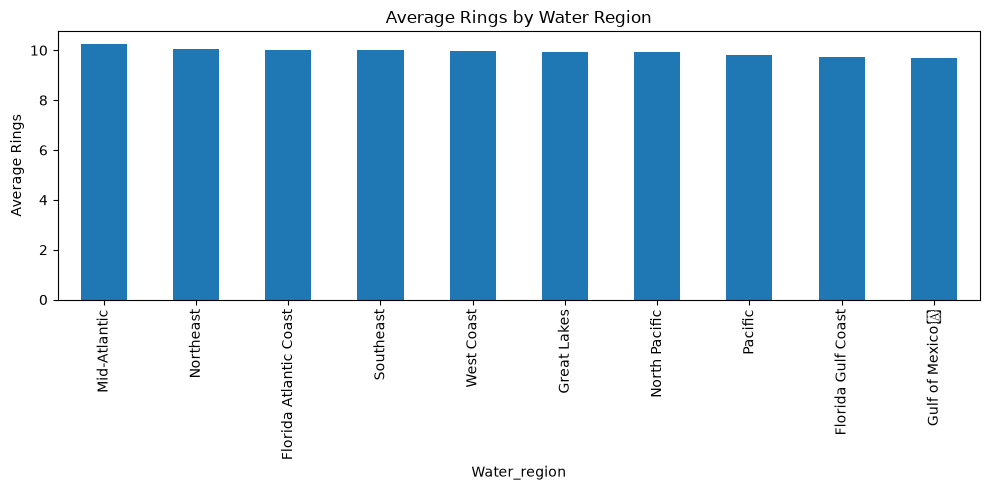

In [10]:
import matplotlib.pyplot as plt

region_age.plot(
    kind="bar",
    figsize=(10,5),
    title="Average Rings by Water Region"
)

plt.ylabel("Average Rings")
plt.tight_layout()
plt.show()

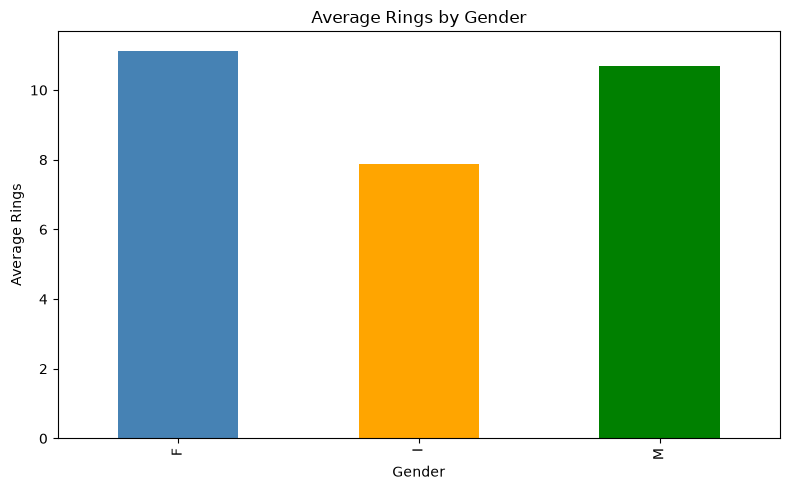

In [11]:
gender_summary.plot(
    kind="bar",
    figsize=(8,5),
    title="Average Rings by Gender",
    color=["steelblue","orange","green"]
)

plt.ylabel("Average Rings")
plt.tight_layout()
plt.show()

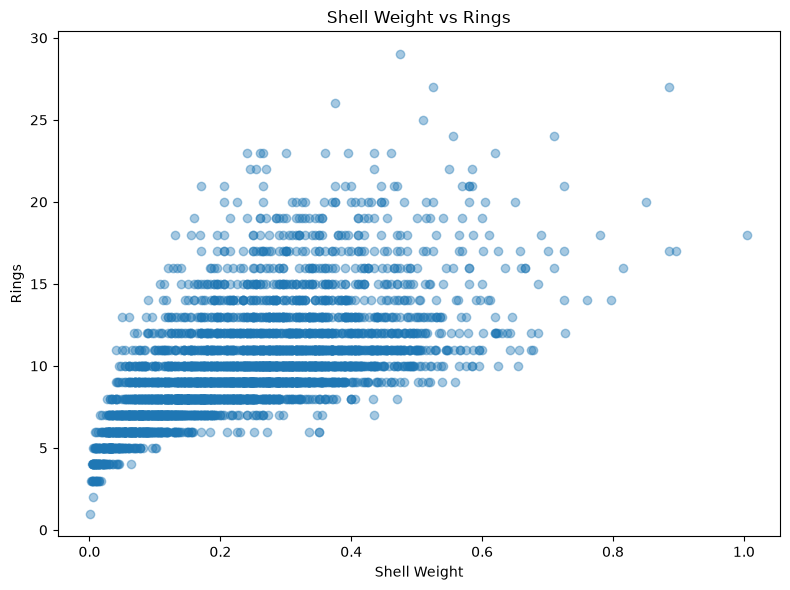

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    df["Shell_weight"],
    df["Rings"],
    alpha=0.4
)

plt.xlabel("Shell Weight")
plt.ylabel("Rings")
plt.title("Shell Weight vs Rings")

plt.tight_layout()
plt.show()

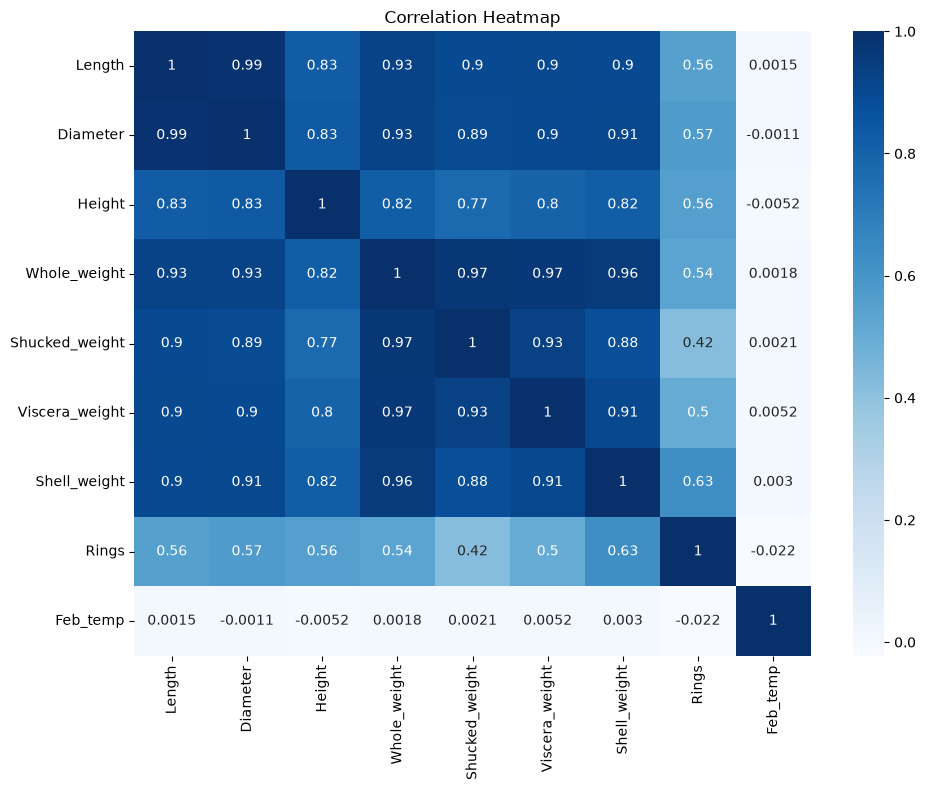

In [13]:
import seaborn as sns

plt.figure(figsize=(10,8))

sns.heatmap(
    df[
        [
            "Length",
            "Diameter",
            "Height",
            "Whole_weight",
            "Shucked_weight",
            "Viscera_weight",
            "Shell_weight",
            "Rings",
            "Feb_temp"
        ]
    ].corr(),
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

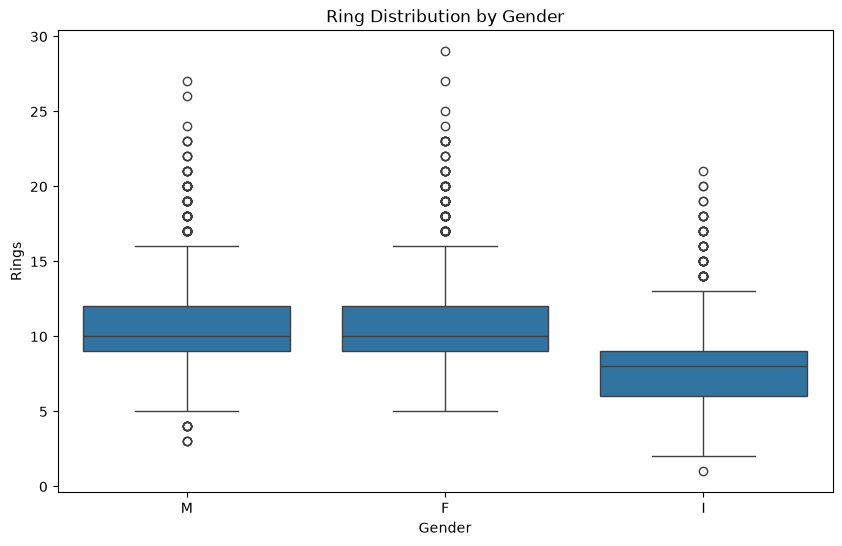

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.boxplot(
    x="Gender",
    y="Rings",
    data=df
)

plt.title("Ring Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Rings")

plt.show()

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

features = [
    "Length",
    "Diameter",
    "Height",
    "Whole_weight",
    "Shucked_weight",
    "Viscera_weight",
    "Shell_weight"
]

X = df[features]
y = df["Rings"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = RandomForestRegressor(
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("R² Score:", r2_score(y_test, predictions))

R² Score: 0.5310548494750849


In [16]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

          Feature  Importance
6    Shell_weight    0.504434
4  Shucked_weight    0.172998
3    Whole_weight    0.086744
5  Viscera_weight    0.069532
2          Height    0.059077
1        Diameter    0.053986
0          Length    0.053230


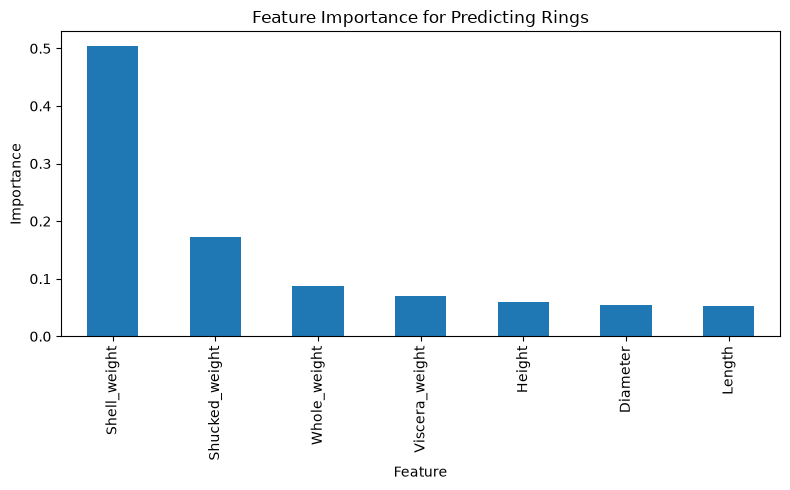

In [17]:
feature_importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    figsize=(8,5),
    title="Feature Importance for Predicting Rings"
)

plt.ylabel("Importance")
plt.tight_layout()
plt.show()

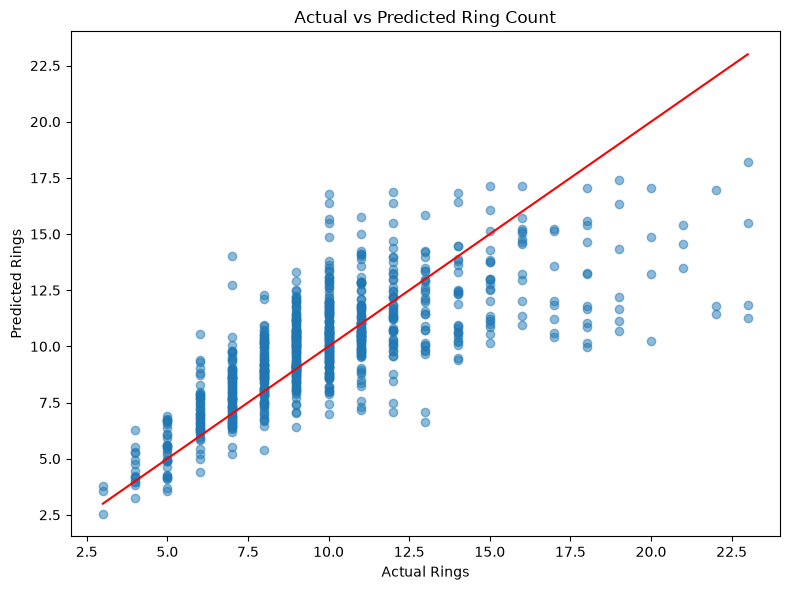

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.5
)

plt.xlabel("Actual Rings")
plt.ylabel("Predicted Rings")
plt.title("Actual vs Predicted Ring Count")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.tight_layout()
plt.show()

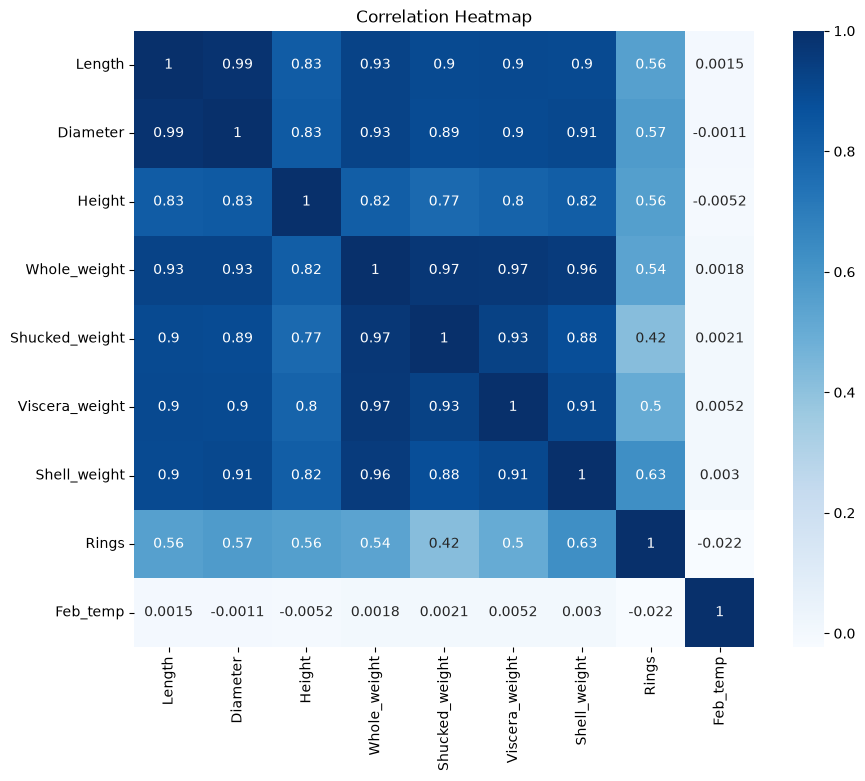

In [19]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df[
        [
            "Length",
            "Diameter",
            "Height",
            "Whole_weight",
            "Shucked_weight",
            "Viscera_weight",
            "Shell_weight",
            "Rings",
            "Feb_temp"
        ]
    ].corr(),
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Heatmap")

plt.savefig(
    "../visualizations/correlation_heatmap.png",
    bbox_inches="tight"
)

plt.show()

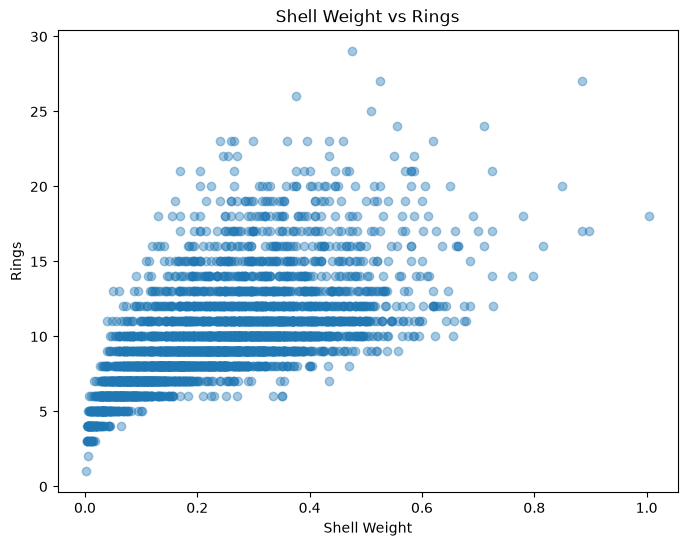

In [20]:
plt.figure(figsize=(8,6))

plt.scatter(
    df["Shell_weight"],
    df["Rings"],
    alpha=0.4
)

plt.xlabel("Shell Weight")
plt.ylabel("Rings")
plt.title("Shell Weight vs Rings")

plt.savefig(
    "../visualizations/shell_weight_vs_rings.png",
    bbox_inches="tight"
)

plt.show()

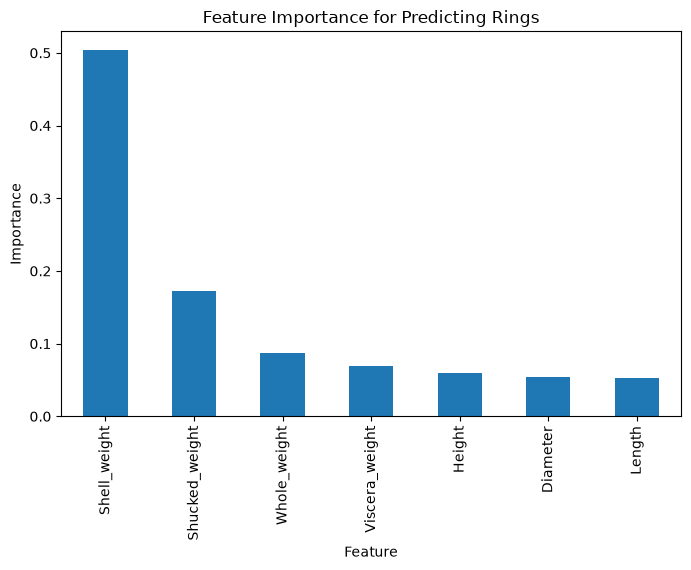

In [21]:
feature_importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    figsize=(8,5),
    title="Feature Importance for Predicting Rings"
)

plt.ylabel("Importance")

plt.savefig(
    "../visualizations/feature_importance.png",
    bbox_inches="tight"
)

plt.show()

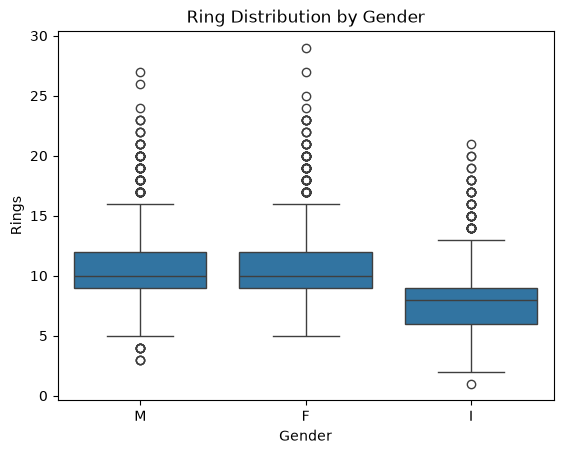

In [22]:
sns.boxplot(
    x="Gender",
    y="Rings",
    data=df
)

plt.title("Ring Distribution by Gender")

plt.savefig(
    "../visualizations/rings_by_gender_boxplot.png",
    bbox_inches="tight"
)

plt.show()